# IBMGO ile regresyon test paketi seçimi

**Kritik kontrolleri ve ön koşulları koruyarak toplam test süresini azaltmak.**

Notebook’u proje klasöründen aç. Ayarları **0. bölümde** değiştirip hücreleri yukarıdan aşağı çalıştır. Tam deney birkaç dakika sürebilir.

In [1]:
# Python dosyalarındaki güncellemeleri açık oturuma da yükle.
%reload_ext autoreload
%autoreload 2

from pathlib import Path

import pandas as pd
from IPython.display import Image, display

from kod.deneyler.notebook_deneyi import deney_planini_hazirla

## 0. Ayarlar

**Hızlı kontrol için** boyutları `[50, 100]`, veri tohumlarını `[83, 97]` seç. Tam koşumda 3 boyut × 5 veri tohumu kullanılır. `A` orijinal, `B` seyrek kritik kapsamlı havuzdur.

`None` otomatik ayar demektir. IBMGO’da otomatik seçenekler boyuta duyarlı profil veya algoritma varsayılanından gelir. GA nesli boşsa, planlanan IBMGO bütçesine en yakın pozitif nesil sayısı seçilir.

In [2]:
# Veri
VERI = dict(
    boyutlar=[500, 1000, 5000],
    tohumlar=[83, 42, 41, 97, 109],
    profil="expanded",           # "standard" veya "expanded"
    seyreltme_adimi=4,           # B: her kritik hedef için her dört eşleşmeden biri
)

# Amaç ve geçerlilik
AMAC = dict(
    asgari_kapsam=0.90,          # Tüm hedefler için alt sınır
    agirliklar=dict(w_time=0.40, w_count=0.40, w_redundancy=0.20, w_rare=0.00),
)

# Arama
ARAMA = dict(
    havuzlar=["A"],             # A ve B'yi eşleştirmek için ["A", "B"]
    algoritma_tohumlari=[42],    # Her tohum IBMGO ve GA için bir tekrar
    populasyon=12,
    ibmgo_tur=20,
    boyuta_adapte=True,
    ibmgo=dict(
        local_search_trials=None,          # None: popülasyon kadar
        spiral_search_trials=0,
        binary_transfer="v_flip",          # "v_flip" veya "s_assign"
        local_search_strategy=None,        # "swap", "large" veya None
        flip_rate_start=0.04,
        flip_rate_end=0.02,
        adaptive_binary=None,
        diverse_initialization=None,
        chaotic_initialization=None,
        reference_mgo_formulas=None,
        reference_mgo_probability=None,
        nonlinear_control=None,
    ),
    ga=dict(max_generations=None, crossover_rate=0.80, mutation_rate=None),
)

# Gösterim ve test sıralaması
GOSTERIM = dict(
    kapsam_boyutu=None,          # None: en büyük test havuzu
    kapsam_tohumu=None,          # None: ilk veri tohumu
    kapsam_hedef_sayisi=8,
    havuz_sayfa_boyu=20,
    oncelik_test_sayisi=5,
    kritik_oncelik_agirligi=3.0,
)

PLAN = deney_planini_hazirla(VERI, AMAC, ARAMA, GOSTERIM)

## 1. Problem

Bir kampanya güncellemesinden sonra yüzlerce test arasından daha kısa bir paket seçiyoruz. Örneğin **ilk faturadaki indirimi** kontrol eden test, **kampanyayı etkinleştiren** testten sonra çalışır. İkisi birlikte seçilmelidir.

Deney sentetik bir telekom sistemi kullanır. Süreler tahminidir ve tasarruflar bu model üzerinden hesaplanır.

## 2. Veri ve test havuzu

`standard` temel kampanyaları kullanır. `expanded` ilk 50 testten sonra ek kampanyalar ve senaryo çeşitleri ekler.

### 2A. Süre ve bağlam duyarlılığı

Aynı boyut ve profilde veri tohumu değişince **senaryolar ve ön koşullar sabit** kalır. Kanal, müşteri bağlamı ve süre değişebilir. Son grafik, aynı test kimliklerini ilk tohumla eşleştirir.

| Veri | Algoritmadaki rolü |
|---|---|
| Kapsam matrisi | Hangi testin hangi hedefi kapsadığını gösterir. |
| Süre dizisi | Seçilen testlerin tahmini süresini toplar. |
| Ön koşul matrisi | Bir test seçildiğinde onunla birlikte hangi testin seçileceğini belirler. |

,Test,Veri tohumu,Kapsam hedefi,Kritik hedef,Ön koşul bağlantısı,Tam paket (dk)
0,500,83,380,151,263,333.0
1,500,42,368,143,263,333.1
2,500,41,392,149,263,334.9
3,500,97,371,144,263,330.1
4,500,109,361,142,263,334.3
5,1000,83,498,190,519,670.0
6,1000,42,514,196,519,671.4
7,1000,41,504,192,519,672.9
8,1000,97,503,192,519,665.4
9,1000,109,517,195,519,672.5


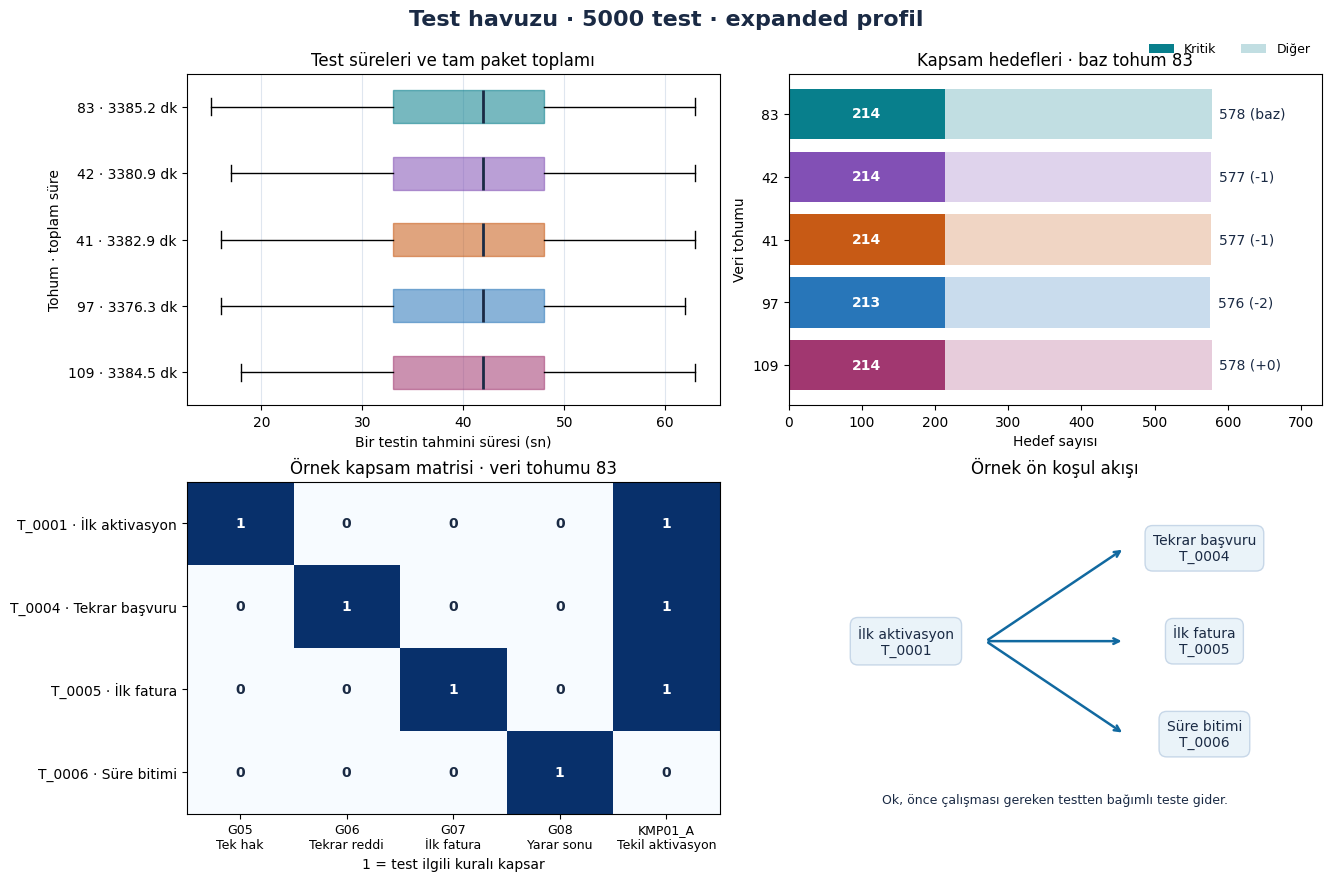

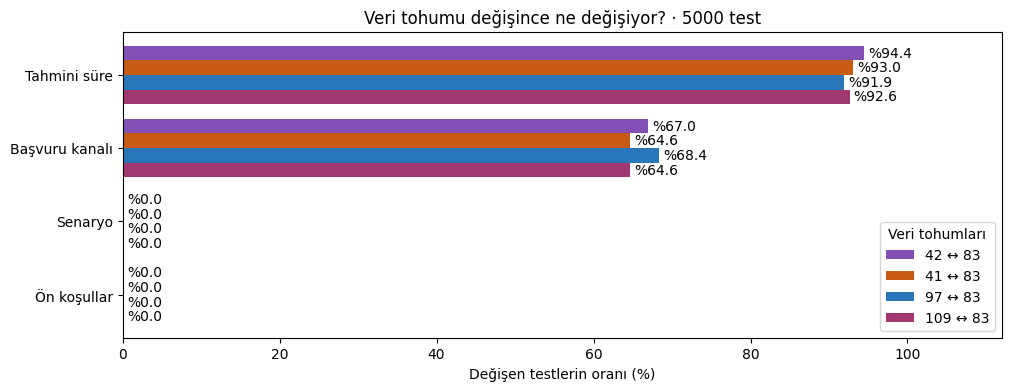

In [3]:
from kod.raporlama.sunum_gorselleri import deney_verisini_goster

deney_verisini_goster(VERI["boyutlar"], VERI["tohumlar"], VERI["profil"])

### Tam test havuzu

Havuzu seçerek süreleri, kapsamı ve ön koşulları gör. Test aralığı menüsüyle tek tek kayıtlara bakabilirsin.

In [4]:
from kod.raporlama.tam_test_havuzu import tam_test_havuzu

display(tam_test_havuzu(
    VERI["boyutlar"], VERI["tohumlar"], VERI["profil"],
    sayfa_boyu=GOSTERIM["havuz_sayfa_boyu"],
))

### 2B. Kritik kapsam duyarlılığı

**A** orijinal havuzdur. B, kapsam matrisinde kontrollü bir zorluk denemesidir. **B** aynı testleri, süreleri ve ön koşulları kullanır. Her kritik hedef için kapsayan testler seyreltilir ve en az bir eşleşme korunur. Seyreltme adımı 4 ise her dört eşleşmeden biri tutulur.

Soldaki panel en çok azalan hedefleri, sağdaki panel tüm kritik hedeflerin kaç testle kapsandığını gösterir.

,Havuz,Test,Toplam hedef,Kapsanan kritik hedef,Ön koşul bağlantısı,Toplam süre (dk),Kritik kapsam eşleşmesi
0,A · Orijinal,5000,578,214,2555,3385.2,14551
1,B · Seyrek kritik kapsam,5000,578,214,2555,3385.2,3721


,Hedef,A · Orijinal,B · Seyrek,Azalma
2,G05,745,187,558
0,G02,500,125,375
4,G07,500,125,375
3,G06,500,125,375
47,G17,495,124,371
6,G09,468,117,351
8,G11,405,102,303
5,G08,335,84,251


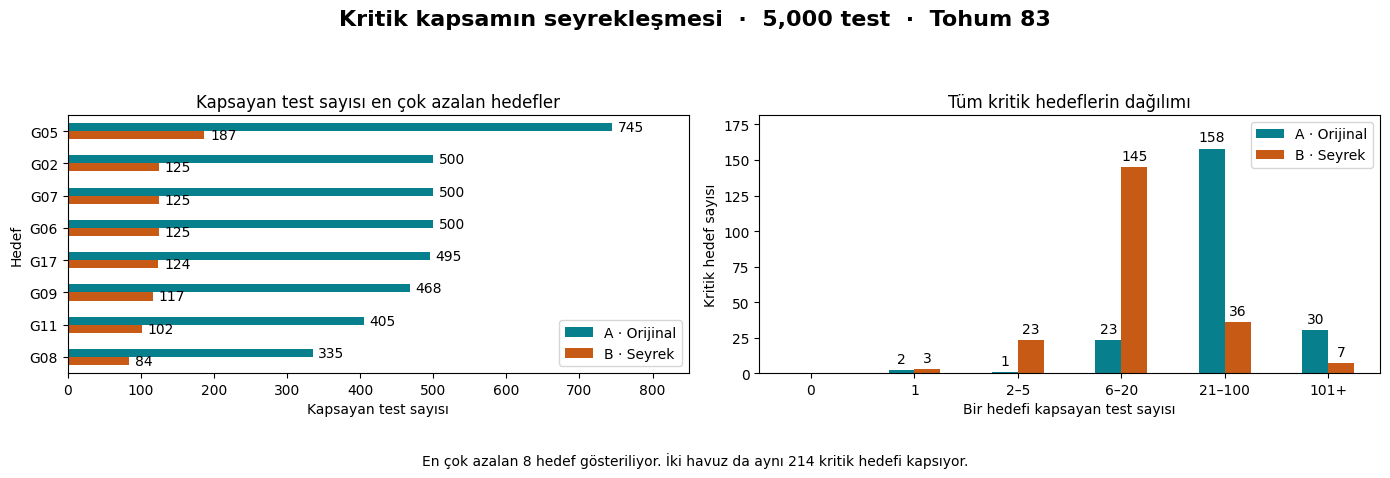

In [5]:
from kod.raporlama.kritik_kapsam import kritik_kapsam_karsilastirmasini_goster

kritik_kapsam_karsilastirmasini_goster(
    GOSTERIM["kapsam_boyutu"] or max(VERI["boyutlar"]),
    VERI["tohumlar"][0] if GOSTERIM["kapsam_tohumu"] is None else GOSTERIM["kapsam_tohumu"],
    VERI["profil"], adim=VERI["seyreltme_adimi"],
    hedef_sayisi=GOSTERIM["kapsam_hedef_sayisi"],
)

## 3. Amaç fonksiyonu

Puan, aşağıdaki oranların ağırlıklı ortalamasıdır. **Düşük puan daha iyi.**

| Ölçüt | Nasıl hesaplanır? | Varsayılan |
|---|---|---:|
| Süre | Seçili süre / toplam süre | %40 |
| Test sayısı | Seçili test / tüm testler | %40 |
| Kapsam tekrarı | İlk isabetin üstündeki eşleşmeler / tüm eşleşmeler | %20 |
| Nadir hedef kaybı | Kaçırılan kritik olmayan hedeflerin nadirlik payı | %0 |

Geçerli paket tüm kritik hedefleri, ayarlanan genel kapsam oranını ve seçili testlerin ön koşullarını korur. Varsayılan genel kapsam eşiği **%90**.

In [6]:
from kod.algoritmalar.fitness import calculate_fitness

### Nadirlik örneği

İki paket aynı sürede aynı sayıda hedefi kapsıyor. Nadirlik, hedefi kapsayan test sayısının tersidir. Örnekte süre %40, test sayısı %30, tekrar %15 ve nadirlik %15 ile puanlanınca nadir hedefi koruyan paket öne geçiyor.

Ana deneyde bu ölçütü açmak için **0. Ayarlar** bölümünde `w_rare` değerini artır. Ağırlıklar toplamlarına bölünerek normalize edilir.

,Paket,Standart puan,Nadirlik eklenince
0,Nadir hedefi kapsayan,0.267,0.283
1,Yaygın hedefi kapsayan,0.267,0.333


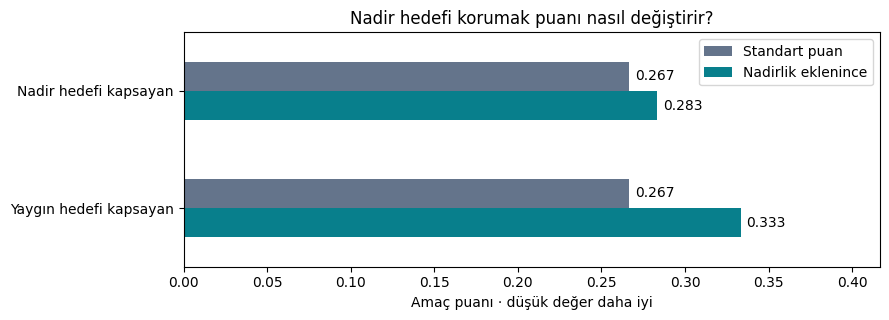

In [7]:
from kod.raporlama.amac_fonksiyonu import nadir_hedef_ornegini_goster

nadir_hedef_ornegini_goster(calculate_fitness)

## 4. Yöntemler

| Yöntem | Aday paket nasıl oluşur? |
|---|---|
| **IBMGO** | Dört MGO hareketiyle adaylar üretir. İkili dönüşüm ve yerel aramayla paketi günceller. |
| **GA** | Seçim, çaprazlama ve mutasyonla yeni adaylar üretir. |
| **Greedy** | Boş paketten başlar. Kapsamı tamamlar ve gereksiz testleri budar. |

Yöntemler aynı kapsam ve ön koşul kurallarına uyar. IBMGO ile GA aynı amaç puanını aramada kullanır. Greedy’nin ürettiği paket aynı puanla değerlendirilir.

## 5. Deney

Her boyut ve veri tohumu için IBMGO ile GA aynı algoritma tohumlarıyla çalışır. Greedy her havuzda bir kez çalışır. Bütçe **planlanan** değerlendirme sayısıdır. B’yi eklediğinde aynı boyut, tohum ve yöntemle A–B karşılaştırması yapılır.

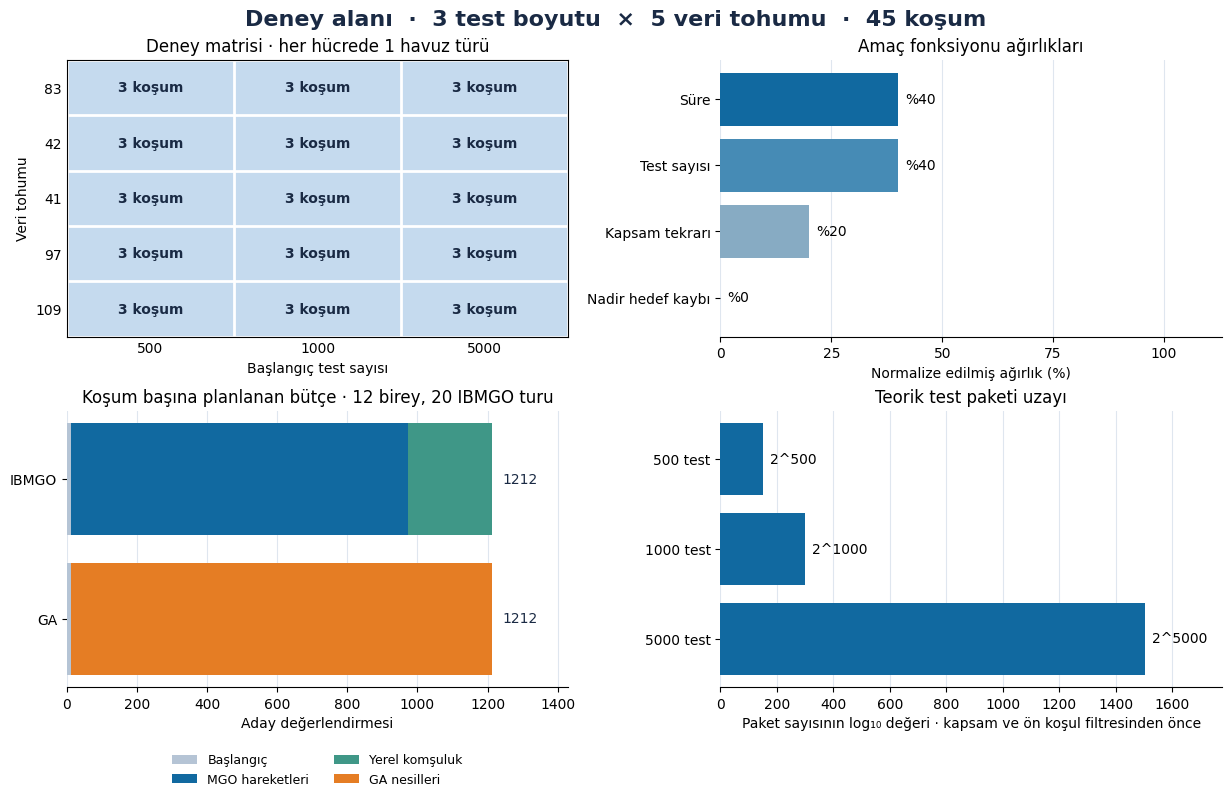

In [8]:
from kod.raporlama.sunum_gorselleri import deney_alanini_ciz

deney_alanini_ciz(
    VERI["boyutlar"], VERI["tohumlar"], len(ARAMA["algoritma_tohumlari"]),
    tuple(AMAC["agirliklar"][ad] for ad in ("w_time", "w_count", "w_redundancy", "w_rare")),
    ARAMA["populasyon"], ARAMA["ibmgo_tur"], PLAN["ibmgo"]["local_search_trials"],
    PLAN["ga_nesil"], spiral_deneme=PLAN["ibmgo"]["spiral_search_trials"],
    havuz_sayisi=len(ARAMA["havuzlar"]),
)

In [9]:
from kod.deneyler.notebook_deneyi import deneyleri_calistir

sonuclar, ornek_secim = deneyleri_calistir(VERI, AMAC, ARAMA, PLAN)

Havuz A · 500 test · veri tohumu 83 tamamlandı.


Havuz A · 500 test · veri tohumu 42 tamamlandı.


Havuz A · 500 test · veri tohumu 41 tamamlandı.


Havuz A · 500 test · veri tohumu 97 tamamlandı.


Havuz A · 500 test · veri tohumu 109 tamamlandı.


Havuz A · 1000 test · veri tohumu 83 tamamlandı.


... (5 outputs left out)

Havuz A · 5000 test · veri tohumu 42 tamamlandı.


Havuz A · 5000 test · veri tohumu 41 tamamlandı.


Havuz A · 5000 test · veri tohumu 97 tamamlandı.


Havuz A · 5000 test · veri tohumu 109 tamamlandı.


## 6. Sonuçlar

**Solda** tahmini süre tasarrufu, **ortada** seçilen test sayısı var. **Sağda** aynı havuz ve tohumla çalışan GA ile IBMGO’nun puan farkı görülür. Sıfırın sağında IBMGO daha düşük puan almıştır. Noktalar koşumları, elmaslar ortalamaları gösterir.

Tabloda kapsam ve ön koşul kontrolleri de yer alır. “Arama süresi” paketi seçmek için geçen süre, “paket süresi” ise testlerin tahmini çalıştırma süresidir.

Koşum  Ort. puan  Ort. seçilen test  \
Havuz Test sayısı Yöntem                                        
A     500         GA          5    0.25789               99.0   
                  Greedy      5    0.28451              109.8   
                  IBMGO       5    0.25642               98.2   
      1000        GA          5    0.22073              140.8   
                  Greedy      5    0.25042              164.2   
                  IBMGO       5    0.22020              140.6   
      5000        GA          5    0.14262              171.0   
                  Greedy      5    0.16323              204.6   
                  IBMGO       5    0.14280              171.0   

                          Ort. paket (dk)  Ort. tasarruf (%)  \
Havuz Test sayısı Yöntem                                       
A     500         GA                 65.4              80.36   
                  Greedy             70.8              78.75   
                  IBMGO              65.3              80.41   
      1000        GA                 92.8              86.16   
                  Greedy            101.4              84.88   
                  IBMGO              92.4              86.22   
      5000        GA                112.0              96.69   
                  Greedy            120.0              96.45   
                  IBMGO             111.3              96.71   

                          En düşük genel kapsam (%)  \
Havuz Test sayısı Yöntem                              
A     500         GA                          90.03   
                  Greedy                      90.03   
                  IBMGO                       90.00   
      1000        GA                          90.06   
                  Greedy                      90.06   
                  IBMGO                       90.06   
      5000        GA                          90.10   
                  Greedy                      90.10   
                  IBMGO                       90.10   

                          En düşük kritik kapsam (%)  Ön koşul ihlali  \
Havuz Test sayısı Yöntem                                                
A     500         GA                           100.0                0   
                  Greedy                       100.0                0   
                  IBMGO                        100.0                0   
      1000        GA                           100.0                0   
                  Greedy                       100.0                0   
                  IBMGO                        100.0                0   
      5000        GA                           100.0                0   
                  Greedy                       100.0                0   
                  IBMGO                        100.0                0   

                          Ort. arama (sn)  
Havuz Test sayısı Yöntem                   
A     500         GA                 5.72  
                  Greedy             0.12  
                  IBMGO              7.93  
      1000        GA                 9.55  
                  Greedy             0.34  
                  IBMGO             15.70  
      5000        GA                44.40  
                  Greedy             2.01  
                  IBMGO             42.79

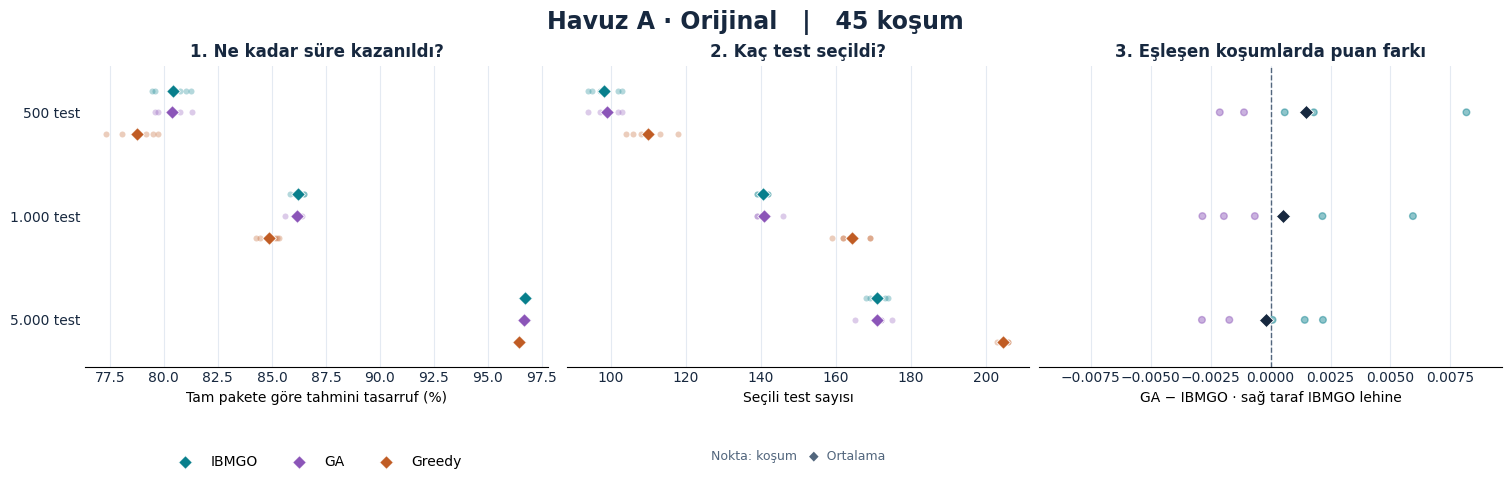

In [10]:
from kod.raporlama.deney_sonuclari import deney_sonuclarini_goster

deney_sonuclarini_goster(sonuclar)

## 7. Önceliklendirme

İlk IBMGO paketinde, ön koşulları tamamlanan testler saniye başına yeni kapsama göre sıralanır. Kritik hedeflerin ağırlığı ve gösterilecek test sayısı **0. Ayarlar** bölümünden değişir. Bu tablo test sırasını gösterir.

In [11]:
from kod.algoritmalar.fitness import prioritize_tests_and_calculate_apfd

havuz, secim, kapsam, sureler, adlar, on_kosullar, kritik, n, veri_tohumu, tohum = ornek_secim
sira, _ = prioritize_tests_and_calculate_apfd(
    secim, kapsam, sureler, dependency_matrix=on_kosullar,
    critical_feature_indices=kritik,
    critical_weight=GOSTERIM["kritik_oncelik_agirligi"],
)
print(f"Havuz {havuz} · {n} test · veri tohumu {veri_tohumu} · algoritma tohumu {tohum}")
display(pd.DataFrame([
    {"Sıra": i, "Test kimliği": f"T_{indeks + 1:04d}", "Senaryo": adlar[indeks],
     "Tahmini süre (sn)": int(sureler[indeks])}
    for i, indeks in enumerate(sira[:GOSTERIM["oncelik_test_sayisi"]], 1)
]))

Havuz A · 500 test · veri tohumu 83 · algoritma tohumu 42


,Sıra,Test kimliği,Senaryo,Tahmini süre (sn)
0,1,T_0161,Genc 20 GB - Uygun musteri icin ilk aktivasyon...,32
1,2,T_0233,Numara Tasima 15 GB - Basvuru penceresi disind...,19
2,3,T_0165,Genc 20 GB - Aktif kampanyanin ilk fatura done...,50
3,4,T_0164,Genc 20 GB - Ayni kampanya hakkinin tekrar kul...,22
4,5,T_0030,Ek 10 GB Paketi - Gecersiz kampanya koduyla ba...,15


## 8. Arşiv · önceki dayanıklılık deneyi

Bu görseller önceki bir çalışmadan alınmıştır. Güncel koşumun sonuçları **6. bölümde** yer alır.

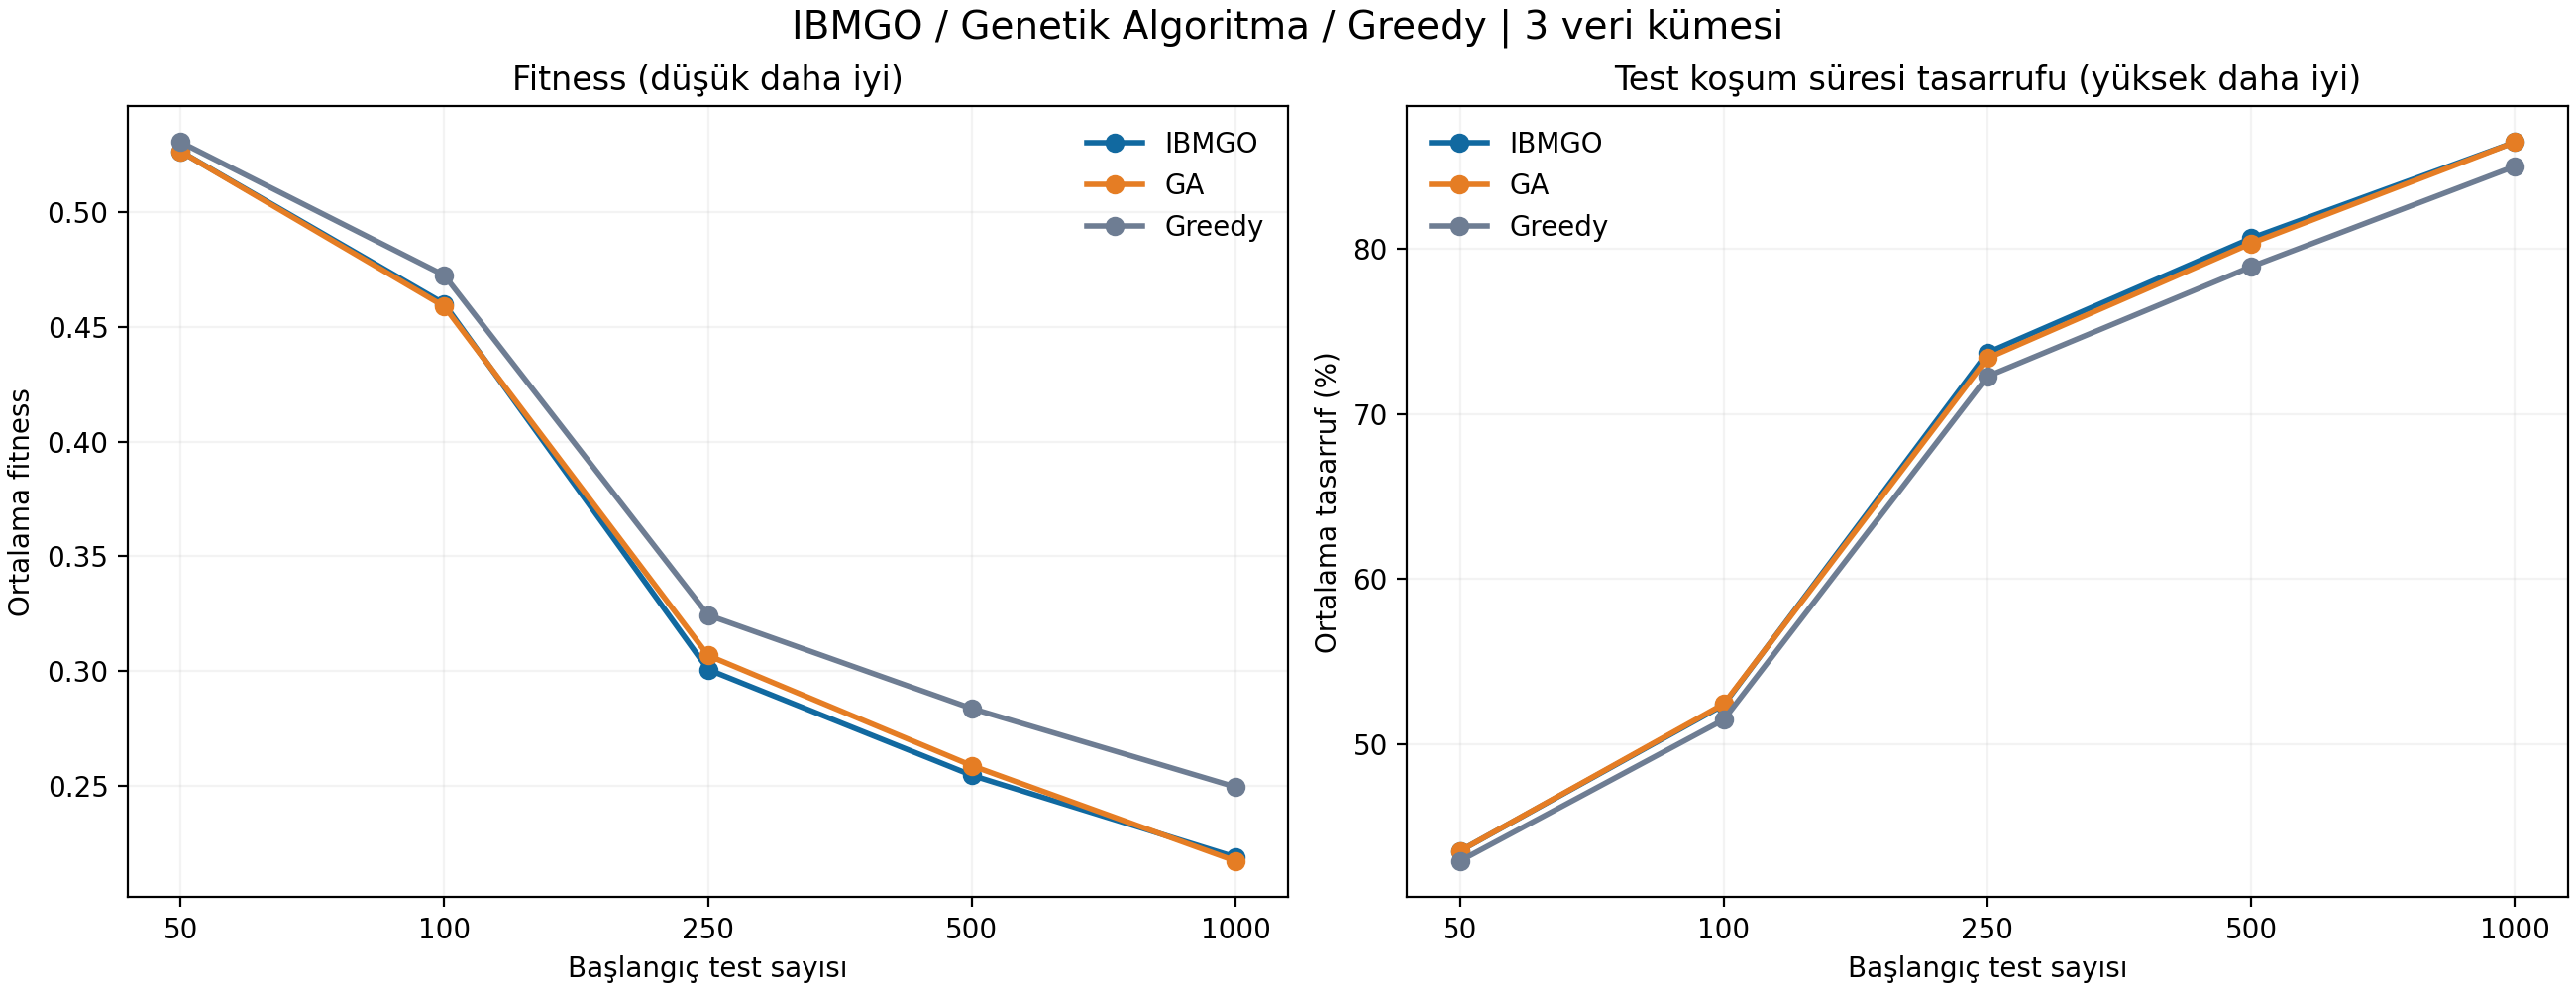

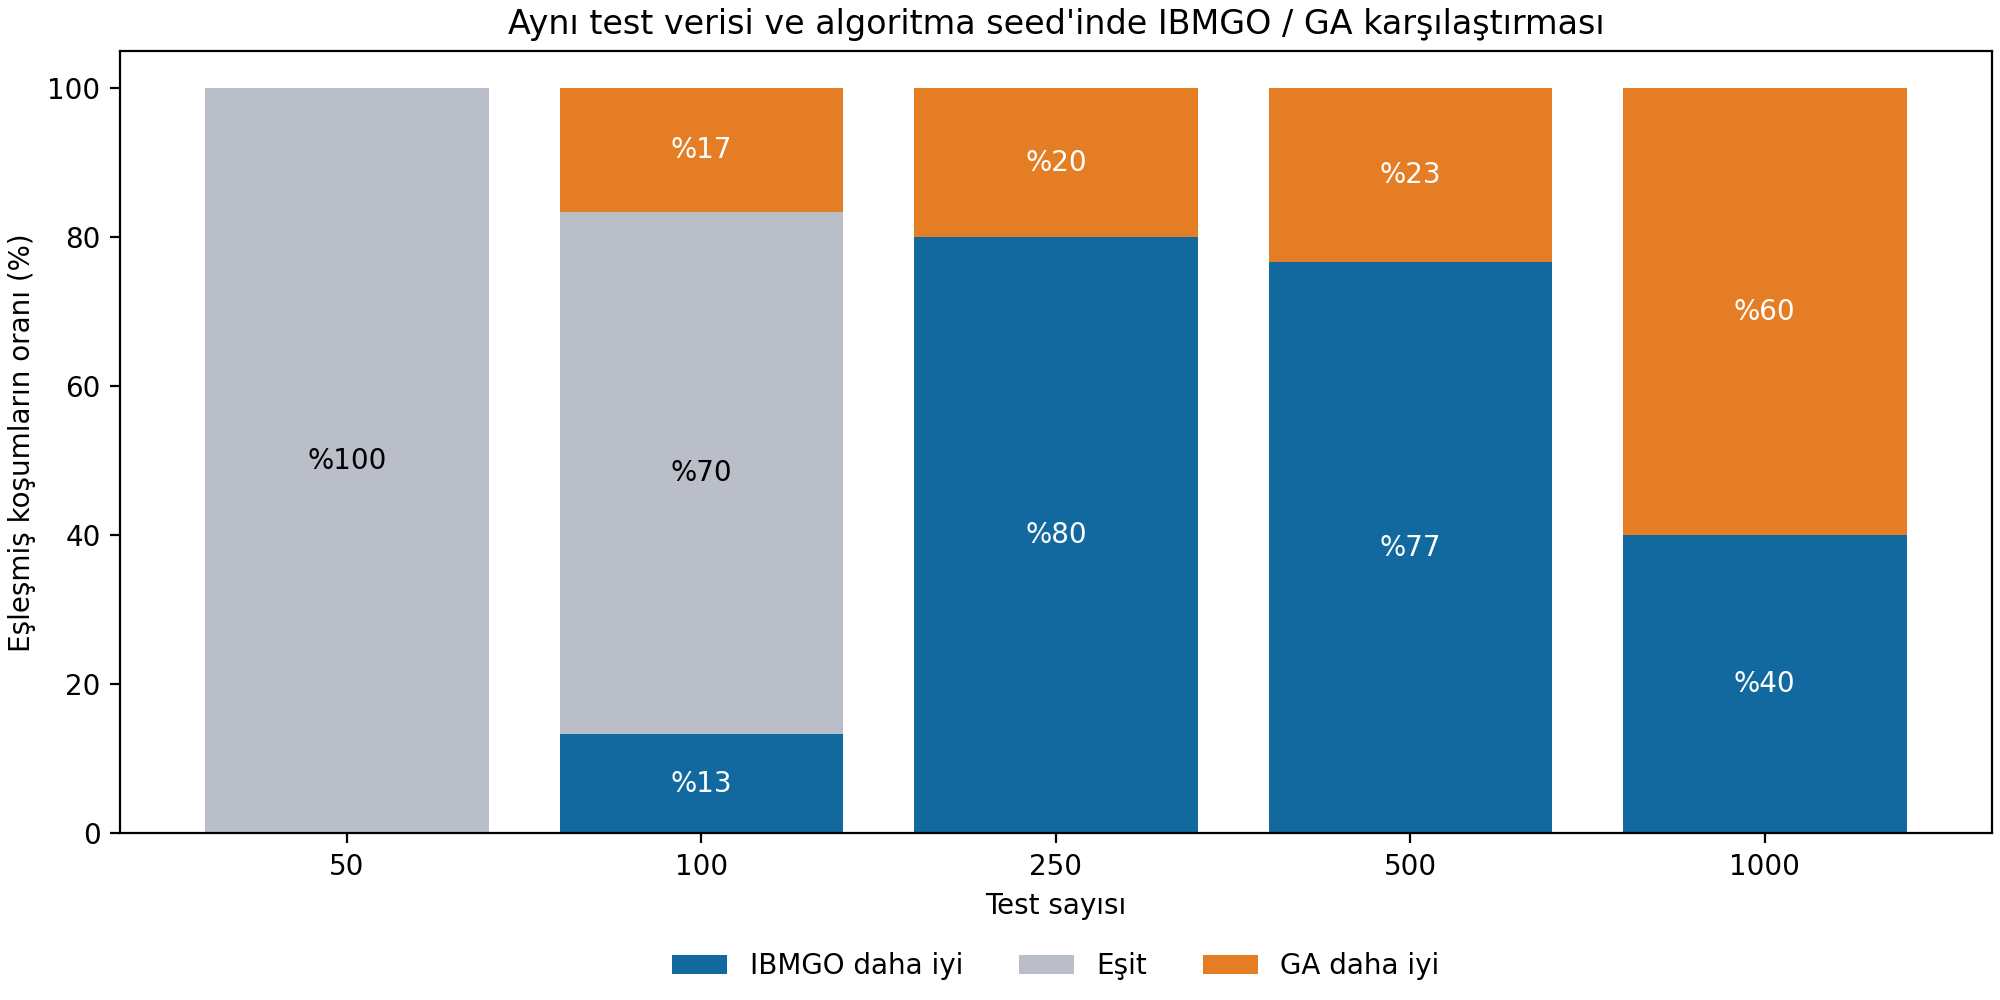

In [12]:
arsiv = Path.cwd() / "sonuclar" / "dayaniklilik_analizi"
display(Image(filename=str(arsiv / "01_ana_karsilastirma.png"), width=940))
display(Image(filename=str(arsiv / "02_eslesmis_kazanma.png"), width=780))